# Where femicide is concentrated

Raw case counts mostly track population, so this notebook compares states by **recorded cases per 100,000 residents**
(2020 Census) across all years in the dataset.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from femicide import load_cases, load_population, top_categories, save

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 11})
ACCENT = "#8E2C48"

In [2]:
cases = load_cases()
pop = load_population()

by_state = (cases["STATE"].value_counts().rename("cases").to_frame()
            .join(pop.rename("population"), how="inner"))
by_state["per_100k"] = by_state["cases"] / by_state["population"] * 1e5
print(f"{by_state['cases'].sum():,} cases across {len(by_state) - 1} states and DC")
by_state.sort_values("per_100k", ascending=False).head(10).round(2)

7,798 cases across 50 states and DC


,cases,population,per_100k
STATE,,,
KY,178,4505836,3.95
MS,115,2961279,3.88
NV,118,3104614,3.80
NC,385,10439388,3.69
MO,220,6154913,3.57
AL,178,5024279,3.54
AK,25,733391,3.41
NM,66,2117522,3.12
LA,144,4657757,3.09


## Raw counts follow population

Large states record the most cases, which is why per-capita rates are the fairer comparison.

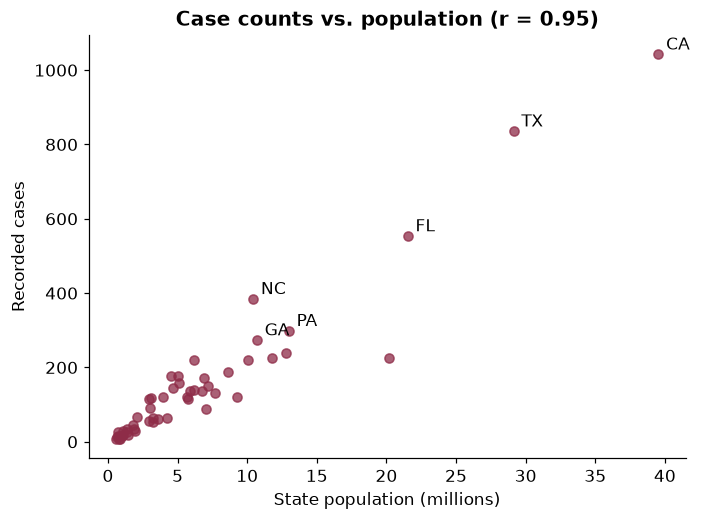

In [3]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(by_state["population"] / 1e6, by_state["cases"], color=ACCENT, alpha=0.75)
for code in by_state.nlargest(6, "cases").index:
    row = by_state.loc[code]
    ax.annotate(code, (row["population"] / 1e6, row["cases"]), xytext=(5, 3), textcoords="offset points")
r = np.corrcoef(by_state["population"], by_state["cases"])[0, 1]
ax.set(xlabel="State population (millions)", ylabel="Recorded cases",
       title=f"Case counts vs. population (r = {r:.2f})")
save(fig, "cases_vs_population.png")

## Per-capita map

Each square is a state, laid out roughly in its geographic position.

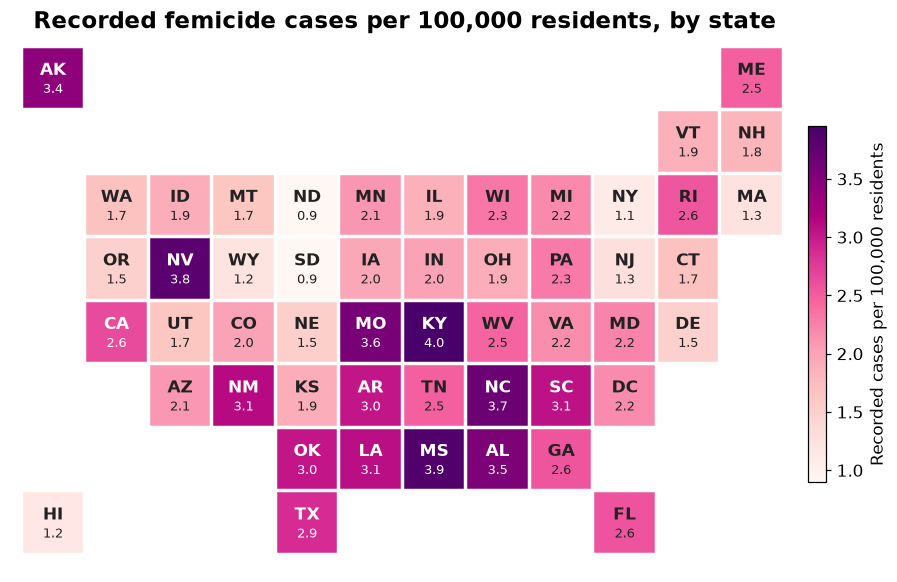

In [4]:
TILES = {
    "AK": (0, 0), "ME": (0, 11), "VT": (1, 10), "NH": (1, 11),
    "WA": (2, 1), "ID": (2, 2), "MT": (2, 3), "ND": (2, 4), "MN": (2, 5), "IL": (2, 6), "WI": (2, 7),
    "MI": (2, 8), "NY": (2, 9), "RI": (2, 10), "MA": (2, 11),
    "OR": (3, 1), "NV": (3, 2), "WY": (3, 3), "SD": (3, 4), "IA": (3, 5), "IN": (3, 6), "OH": (3, 7),
    "PA": (3, 8), "NJ": (3, 9), "CT": (3, 10),
    "CA": (4, 1), "UT": (4, 2), "CO": (4, 3), "NE": (4, 4), "MO": (4, 5), "KY": (4, 6), "WV": (4, 7),
    "VA": (4, 8), "MD": (4, 9), "DE": (4, 10),
    "AZ": (5, 2), "NM": (5, 3), "KS": (5, 4), "AR": (5, 5), "TN": (5, 6), "NC": (5, 7), "SC": (5, 8),
    "DC": (5, 9),
    "OK": (6, 4), "LA": (6, 5), "MS": (6, 6), "AL": (6, 7), "GA": (6, 8),
    "HI": (7, 0), "TX": (7, 4), "FL": (7, 9),
}

rate = by_state["per_100k"]
norm = plt.Normalize(rate.min(), rate.max())
cmap = plt.get_cmap("RdPu")

fig, ax = plt.subplots(figsize=(11, 7))
for code, (row, col) in TILES.items():
    value = rate.get(code, np.nan)
    color = cmap(norm(value)) if pd.notna(value) else "#e5e5e5"
    ax.add_patch(plt.Rectangle((col, -row), 0.92, 0.92, color=color))
    text_color = "white" if pd.notna(value) and norm(value) > 0.55 else "#222"
    ax.text(col + 0.46, -row + 0.58, code, ha="center", va="center", fontweight="bold", color=text_color)
    ax.text(col + 0.46, -row + 0.28, f"{value:.1f}" if pd.notna(value) else "–", ha="center",
            va="center", fontsize=8.5, color=text_color)
ax.set(xlim=(-0.2, 12.2), ylim=(-7.3, 1.1), aspect="equal")
ax.axis("off")
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.01, label="Recorded cases per 100,000 residents")
ax.set_title("Recorded femicide cases per 100,000 residents, by state", fontsize=15)
save(fig, "per_capita_map.png")

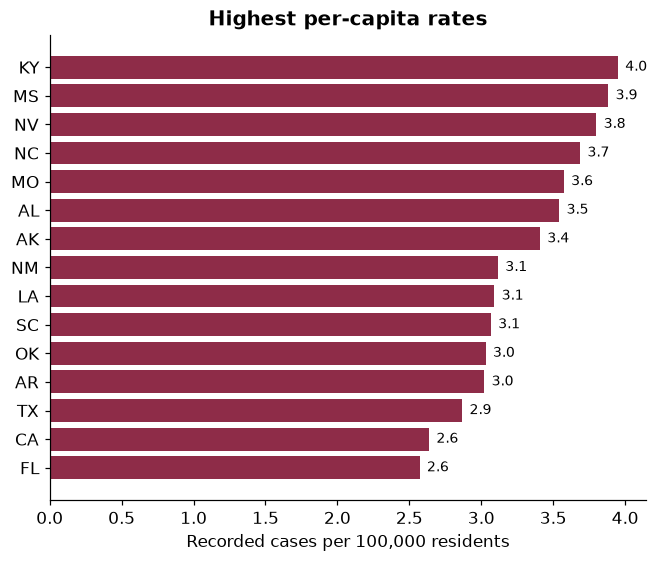

In [5]:
fig, ax = plt.subplots(figsize=(7, 5.5))
top = rate.sort_values().tail(15)
ax.barh(top.index, top.values, color=ACCENT)
ax.set(xlabel="Recorded cases per 100,000 residents", title="Highest per-capita rates")
for y, v in enumerate(top.values):
    ax.text(v + 0.05, y, f"{v:.1f}", va="center", fontsize=9)
save(fig, "top_states_per_capita.png")

## Notes

- Rates use total resident population, and the dataset's coverage varies by year and state, so they describe
  **recorded** cases rather than true incidence.
- A county-level version would show local hotspots that state totals hide.